In [1]:
import duckdb

# Connect to DuckDB (in-memory)
con = duckdb.connect(database=':memory:')

print("Computing descriptive statistics for trip_distance on the clean dataset...")

# DuckDB query using quantile_cont for median and quartiles (IQR), 
# alongside built-in mean, stddev, and skewness functions.
stats_query = """
SELECT 
    COUNT(trip_distance) AS total_valid_trips,
    AVG(trip_distance) AS mean_val,
    QUANTILE_CONT(trip_distance, 0.25) AS q1,
    QUANTILE_CONT(trip_distance, 0.5) AS median_val,
    QUANTILE_CONT(trip_distance, 0.75) AS q3,
    STDDEV(trip_distance) AS std_val,
    QUANTILE_CONT(trip_distance, 0.75) - QUANTILE_CONT(trip_distance, 0.25) AS iqr_val,
    SKEWNESS(trip_distance) AS skewness_val
FROM "../data/raw/yellow_tripdata_2025-*.parquet";
"""

df_stats = con.execute(stats_query).df()
con.close()
x = 10
print("\n--- Statistical Summary for trip_distance before cleaning ---")
print(df_stats.to_string(index=False))

Computing descriptive statistics for trip_distance on the clean dataset...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


--- Statistical Summary for trip_distance before cleaning ---
 total_valid_trips  mean_val   q1  median_val  q3    std_val  iqr_val  skewness_val
          48722602  6.842892 1.04        1.85 3.7 649.361331     2.66    240.904685


In [2]:
import duckdb

con = duckdb.connect(database=':memory:')

print("Computing descriptive statistics for fare_amount on the clean dataset...")

stats_query = """
SELECT 
    COUNT(fare_amount) AS total_valid_trips,
    AVG(fare_amount) AS mean_val,
    QUANTILE_CONT(fare_amount, 0.25) AS q1,
    QUANTILE_CONT(fare_amount, 0.5) AS median_val,
    QUANTILE_CONT(fare_amount, 0.75) AS q3,
    STDDEV(fare_amount) AS std_val,
    QUANTILE_CONT(fare_amount, 0.75) - QUANTILE_CONT(fare_amount, 0.25) AS iqr_val,
    SKEWNESS(fare_amount) AS skewness_val
FROM '../data/raw/yellow_tripdata_2025-*.parquet';
"""

df_stats = con.execute(stats_query).df()
con.close()

print("\n--- Statistical Summary for fare_amount before cleaning ---")
print(df_stats.to_string(index=False))

Computing descriptive statistics for fare_amount on the clean dataset...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


--- Statistical Summary for fare_amount before cleaning ---
 total_valid_trips  mean_val  q1  median_val   q3    std_val  iqr_val  skewness_val
          48722602 18.419376 8.6       13.58 22.6 142.846068     14.0    5030.23568


In [5]:
import duckdb

con = duckdb.connect(database=':memory:')

print("Computing descriptive statistics for tip_amount on the clean dataset...")

stats_query = """
SELECT 
    COUNT(tip_amount) AS total_valid_trips,
    AVG(tip_amount) AS mean_val,
    QUANTILE_CONT(tip_amount, 0.25) AS q1,
    QUANTILE_CONT(tip_amount, 0.5) AS median_val,
    QUANTILE_CONT(tip_amount, 0.75) AS q3,
    STDDEV(tip_amount) AS std_val,
    QUANTILE_CONT(tip_amount, 0.75) - QUANTILE_CONT(tip_amount, 0.25) AS iqr_val,
    SKEWNESS(tip_amount) AS skewness_val
FROM '../data/raw/yellow_tripdata_2025-*.parquet';
"""

df_stats = con.execute(stats_query).df()
con.close()

print("\n--- Statistical Summary for tip_amount before cleaning ---")
print(df_stats.to_string(index=False))

Computing descriptive statistics for tip_amount on the clean dataset...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


--- Statistical Summary for tip_amount before cleaning ---
 total_valid_trips  mean_val  q1  median_val   q3  std_val  iqr_val  skewness_val
          48722602  2.842251 0.0         2.0 3.99 3.966758     3.99      5.282444


In [6]:
import duckdb

con = duckdb.connect(database=':memory:')

print("Computing descriptive statistics for trip_duration_minutes on the clean dataset...")

stats_query = """
WITH clean_filtered AS (
    SELECT 
        EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) / 60.0 AS trip_duration_minutes
    FROM '../data/raw/yellow_tripdata_2025-*.parquet'
)
SELECT 
    COUNT(trip_duration_minutes) AS total_valid_trips,
    AVG(trip_duration_minutes) AS mean_val,
    QUANTILE_CONT(trip_duration_minutes, 0.25) AS q1,
    QUANTILE_CONT(trip_duration_minutes, 0.5) AS median_val,
    QUANTILE_CONT(trip_duration_minutes, 0.75) AS q3,
    STDDEV(trip_duration_minutes) AS std_val,
    QUANTILE_CONT(trip_duration_minutes, 0.75) - QUANTILE_CONT(trip_duration_minutes, 0.25) AS iqr_val,
    SKEWNESS(trip_duration_minutes) AS skewness_val
FROM clean_filtered;
"""

df_stats = con.execute(stats_query).df()
con.close()

print("\n--- Statistical Summary for trip_duration_minutes before cleaning ---")
print(df_stats.to_string(index=False))

Computing descriptive statistics for trip_duration_minutes on the clean dataset...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


--- Statistical Summary for trip_duration_minutes before cleaning ---
 total_valid_trips  mean_val       q1  median_val        q3   std_val   iqr_val  skewness_val
          48722602 17.355859 8.116667   13.483333 21.483333 28.291058 13.366667    -69.375436


Extracting a representative sample of clean trip durations from processed data...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Loaded 484,686 sampled records for plotting.
Generating trip duration distribution plot...


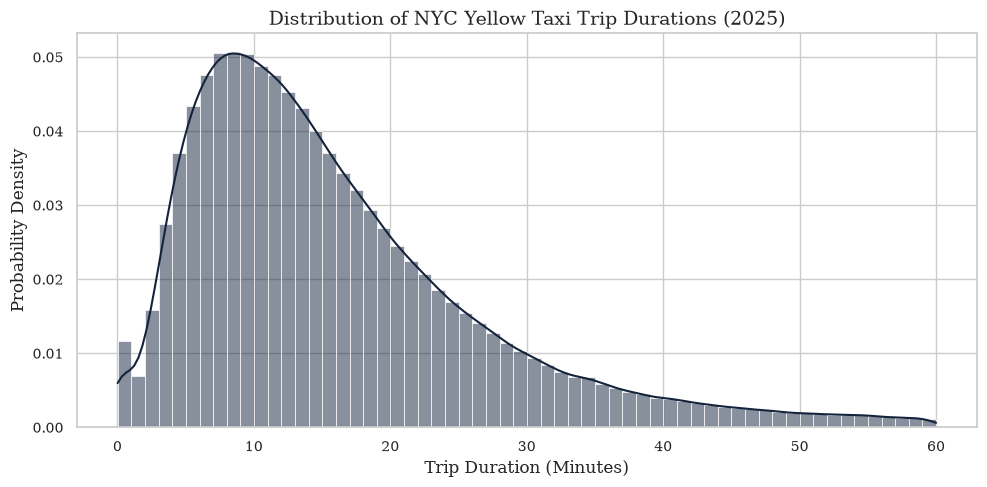

Plot successfully generated and saved to '../reports/figures/trip_duration_distribution.png'!


In [7]:
import duckdb
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style for professional reports
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 14,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'figure.autolayout': True
})

# Connect to DuckDB in-memory database
con = duckdb.connect(database=':memory:')

print("Extracting a representative sample of clean trip durations from processed data...")

# Query processed data, calculating duration in minutes, capping at 60 mins for visualization
query = """
SELECT 
    EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) / 60.0 AS trip_duration_minutes
FROM '../data/raw/yellow_tripdata_2025-*.parquet'
WHERE 
    EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) / 60.0 > 0
    AND EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) / 60.0 <= 60
USING SAMPLE 500000;
"""

df_duration = con.execute(query).df()
con.close()

print(f"Loaded {len(df_duration):,} sampled records for plotting.")

print("Generating trip duration distribution plot...")
plt.figure(figsize=(10, 5))

# Plot histogram with a Kernel Density Estimate (KDE) curve
ax = sns.histplot(
    df_duration['trip_duration_minutes'], 
    bins=60, 
    kde=True, 
    color='#14233C', 
    stat='density',
    edgecolor='white',
    linewidth=0.5
)

plt.title('Distribution of NYC Yellow Taxi Trip Durations (2025)')
plt.xlabel('Trip Duration (Minutes)')
plt.ylabel('Probability Density')

# Save figure for your LaTeX report
plt.savefig('../reports/figures/trip_duration_distribution_precleansing.png', dpi=300)
plt.show()

print("Plot successfully generated and saved to '../reports/figures/trip_duration_distribution.png'!")

In [8]:
import duckdb

con = duckdb.connect(database=':memory:')

print("Computing descriptive statistics for trip speed (mph) on the clean dataset...")

stats_query = """
WITH clean_filtered AS (
    SELECT 
        CASE 
            WHEN EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) > 0 
            THEN trip_distance / (EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) / 3600.0)
            ELSE NULL 
        END AS speed_mph
    FROM '../data/raw/yellow_tripdata_2025-*.parquet'
)
SELECT 
    COUNT(speed_mph) AS total_valid_trips,
    AVG(speed_mph) AS mean_val,
    QUANTILE_CONT(speed_mph, 0.25) AS q1,
    QUANTILE_CONT(speed_mph, 0.5) AS median_val,
    QUANTILE_CONT(speed_mph, 0.75) AS q3,
    STDDEV(speed_mph) AS std_val,
    QUANTILE_CONT(speed_mph, 0.75) - QUANTILE_CONT(speed_mph, 0.25) AS iqr_val,
    SKEWNESS(speed_mph) AS skewness_val
FROM clean_filtered
WHERE speed_mph IS NOT NULL AND speed_mph <= 80 AND speed_mph > 0;
"""

df_stats = con.execute(stats_query).df()
con.close()

print("\n--- Statistical Summary for speed_mph before cleaning ---")
print(df_stats.to_string(index=False))

Computing descriptive statistics for trip speed (mph) on the clean dataset...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


--- Statistical Summary for speed_mph before cleaning ---
 total_valid_trips  mean_val       q1  median_val    q3  std_val  iqr_val  skewness_val
          46775191 11.061362 7.012987    9.483871 13.14 6.402613 6.127013      1.828944
